<a href="https://colab.research.google.com/github/DAlarconAlarcon/Mineria-de-datos/blob/main/LAB%202.8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import kagglehub
from google.colab import userdata

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")



def metricas(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

def grafico_regresion(x, y, modelo, titulo):
    # x e y son Series; el modelo es una regresión simple ya ajustada
    plt.figure(figsize=(6, 4.5))
    plt.scatter(x, y, alpha=0.5, s=15)
    xs = pd.DataFrame({x.name: np.linspace(x.min(), x.max(), 100)})
    plt.plot(xs[x.name], modelo.predict(xs), color="red")
    plt.xlabel(x.name); plt.ylabel(y.name); plt.title(titulo)
    plt.tight_layout(); plt.show()

def grafico_residuos(y_true, y_pred, titulo):
    res = np.asarray(y_true) - np.asarray(y_pred)
    plt.figure(figsize=(6, 4.5))
    plt.scatter(y_pred, res, alpha=0.5, s=15)
    plt.axhline(0, color="red", linestyle="--")
    plt.xlabel("Predichos"); plt.ylabel("Residuos"); plt.title(titulo)
    plt.tight_layout(); plt.show()

def hist_box(df, cols):
    fig, axes = plt.subplots(2, len(cols), figsize=(4.2 * len(cols), 6), squeeze=False)
    for j, c in enumerate(cols):
        sns.histplot(df[c].dropna(), kde=True, ax=axes[0, j]); axes[0, j].set_title(c)
        sns.boxplot(y=df[c].dropna(), ax=axes[1, j])
    plt.tight_layout(); plt.show()
print("llega hasta acá")

llega hasta acá


Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
['data.csv']
(569, 33)
float64    31
int64       1
object      1
Name: count, dtype: int64
Unnamed: 32    569
dtype: int64


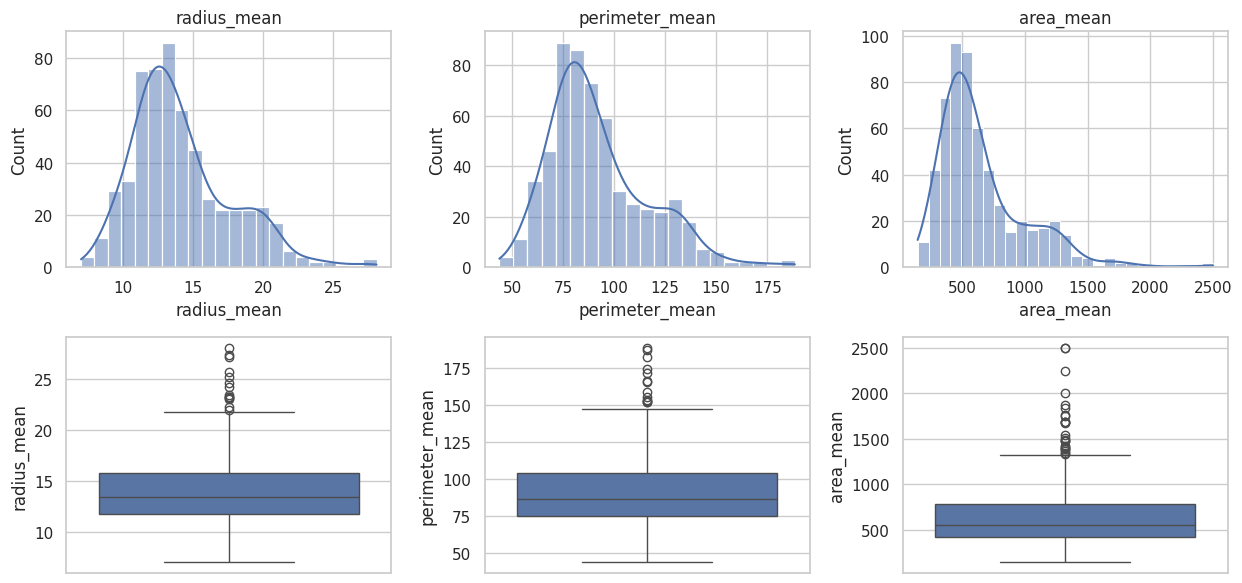

llega hasta acá 2 


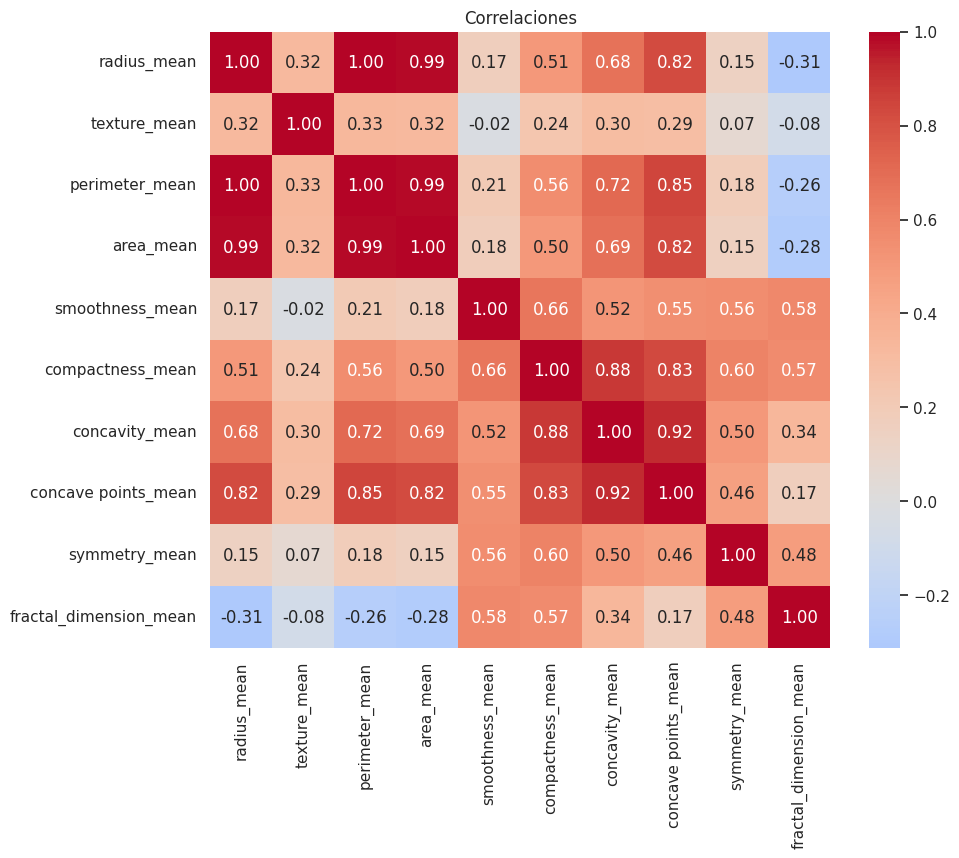

Perímetro: pendiente 6.880400289601538 intercepto -5.232388786540255
Área:      pendiente 98.59821921514533 intercepto -738.0367041957495
llega hasta acá 3 


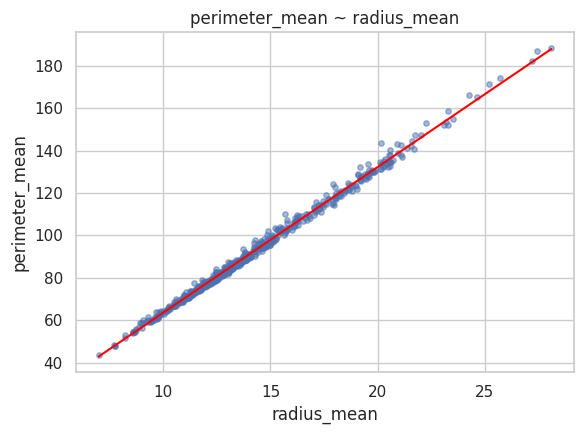

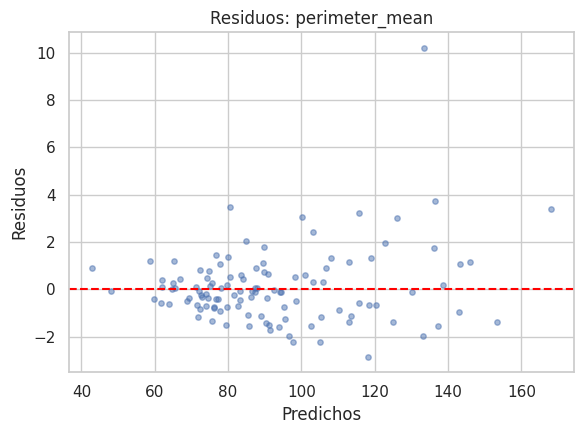

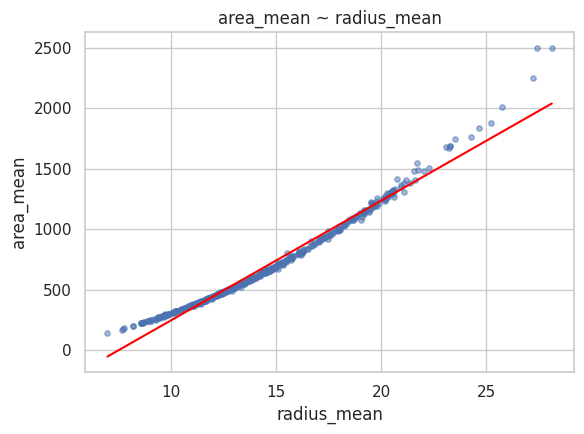

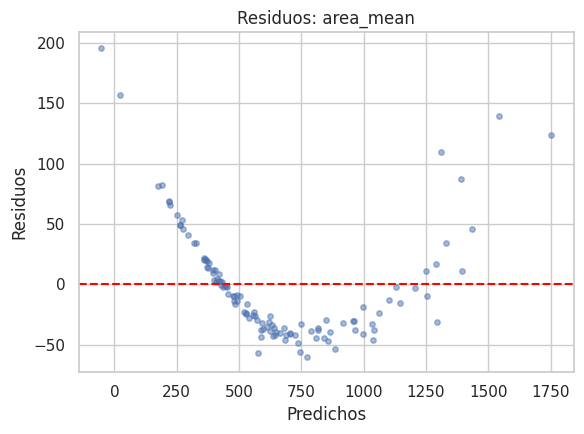

In [11]:
ruta1 = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print(os.listdir(ruta1))
df = pd.read_csv(os.path.join(ruta1, "data.csv"))
print(df.shape)
print(df.dtypes.value_counts())
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head()
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")
hist_box(df, ["radius_mean", "perimeter_mean", "area_mean"])
print("llega hasta acá 2 ")
cols_mean = [c for c in df.columns if c.endswith("_mean")]
plt.figure(figsize=(10, 8))
sns.heatmap(df[cols_mean].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones"); plt.show()
X = df[["radius_mean"]]
m_per = LinearRegression().fit(X, df["perimeter_mean"])
m_area = LinearRegression().fit(X, df["area_mean"])

print("Perímetro: pendiente", m_per.coef_[0], "intercepto", m_per.intercept_)
print("Área:      pendiente", m_area.coef_[0], "intercepto", m_area.intercept_)
resultados, guardados = {}, {}
for objetivo in ["perimeter_mean", "area_mean"]:
    X_tr, X_te, y_tr, y_te = train_test_split(df[["radius_mean"]], df[objetivo],
                                              test_size=0.2, random_state=RANDOM_STATE)
    m = LinearRegression().fit(X_tr, y_tr)
    pred = m.predict(X_te)
    resultados[objetivo] = metricas(y_te, pred)
    guardados[objetivo] = (m, y_te, pred)
print("llega hasta acá 3 ")
pd.DataFrame(resultados).T
for objetivo, (m, y_te, pred) in guardados.items():
    grafico_regresion(df["radius_mean"], df[objetivo], m, f"{objetivo} ~ radius_mean")
    grafico_residuos(y_te, pred, f"Residuos: {objetivo}")

##**EL DATASET DEL FIFA FUE ELIMINADO**

In [32]:
HANDLE = "debayank2024/netflix-movies-and-series"
ruta3 = kagglehub.dataset_download(HANDLE)
print(os.listdir(ruta3))

ARCHIVO = "netflix_titles.csv"   # el que viste en la salida anterior
OBJETIVO = "columna_objetivo"               # lo defines después del EDA inicial
SEGMENTO = ""             # o None si no se puede segmentar

df3 = pd.read_csv(os.path.join(ruta3, ARCHIVO))
print(df3.shape)
print(df3.dtypes)
print(df3.isnull().sum()[df3.isnull().sum() > 0])
df3.head()

Using Colab cache for faster access to the 'netflix-movies-and-series' dataset.
['netflix_titles.csv']
(8807, 12)
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object
director      2634
cast           825
country        831
date_added      10
rating           4
duration         3
dtype: int64


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


##**EL DATASET UTILIZADO EN EL PRIMER LAB NO SIRVE, YA QUE SOLO CUENTA CON UNA VARIABLE NUMERICA (RELEASE_YEAR) EL CUAL SU RANGO NO ES MUY AMPLIO, OTRA OPCION PODIRA SER LA VARIABLE DURATION, PERO NO SE CONSIDERARA YA QUE ESTA EN TEXTO**

#**SE UTILIZARA EL DATASET [$$rashikrahmanpritom/groceries-dataset-for-market-basket-analysismba$$] PARA REALIZAR EL TERCER PUNTO**

Using Colab cache for faster access to the 'groceries-dataset-for-market-basket-analysismba' dataset.
['Groceries data.csv', 'basket.csv']
(38765, 7)
Member_number       int64
Date               object
itemDescription    object
year                int64
month               int64
day                 int64
day_of_week         int64
dtype: object
Series([], dtype: int64)
(728, 10) 2014-01-01 00:00:00 2015-12-30 00:00:00


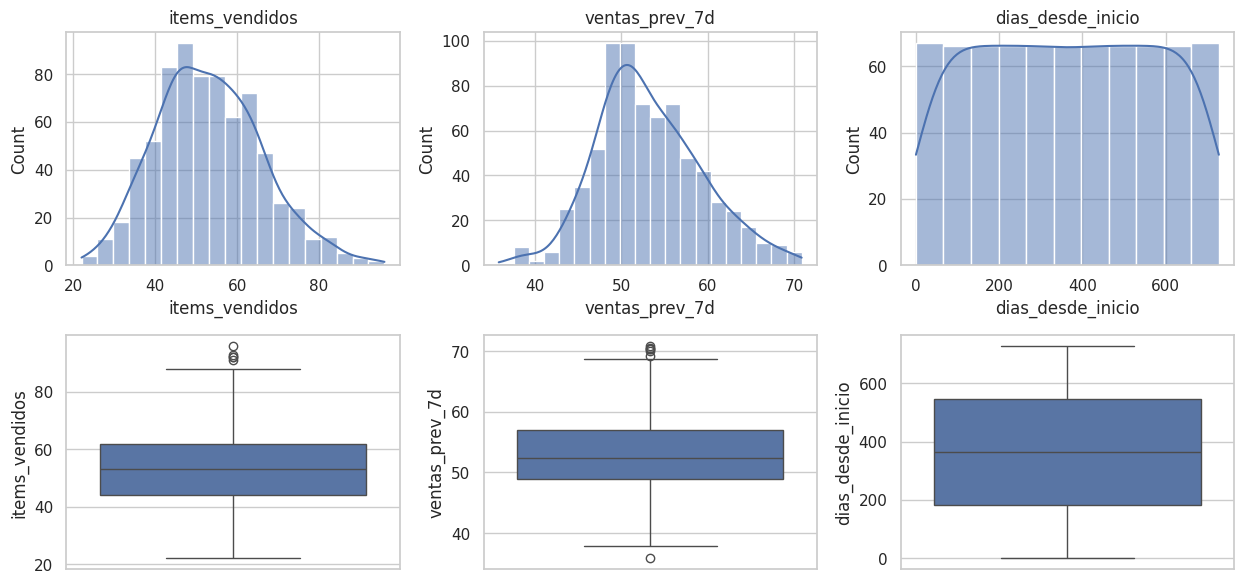

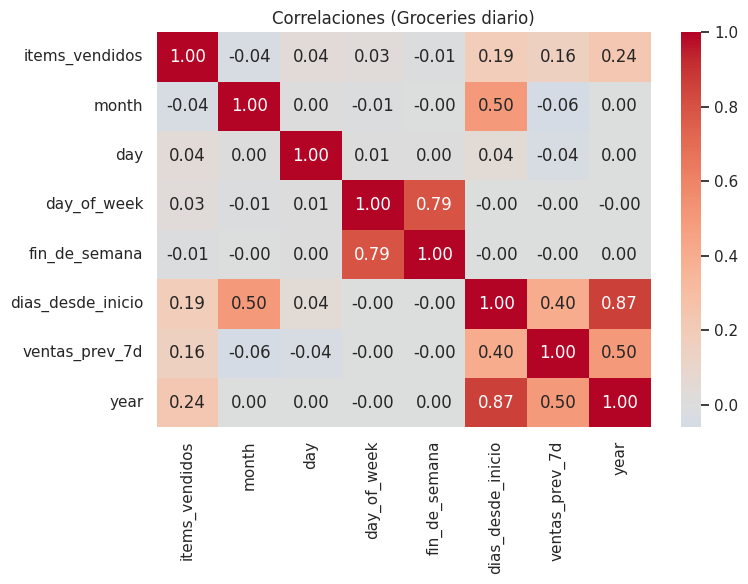

year                 0.235391
dias_desde_inicio    0.185522
ventas_prev_7d       0.157841
month               -0.040087
day                  0.035127
day_of_week          0.029916
fin_de_semana       -0.012894
Name: items_vendidos, dtype: float64


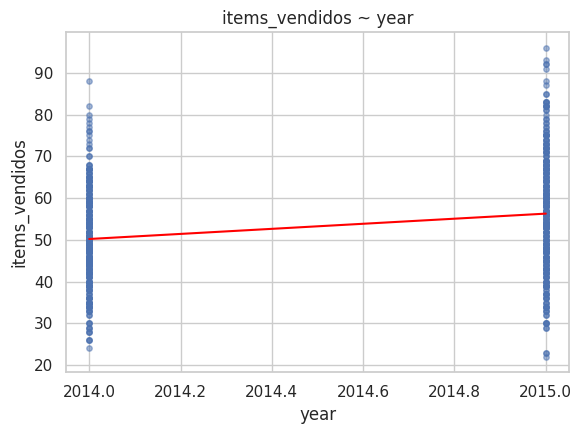

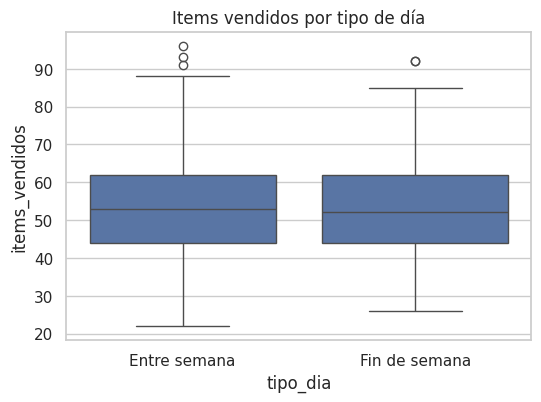

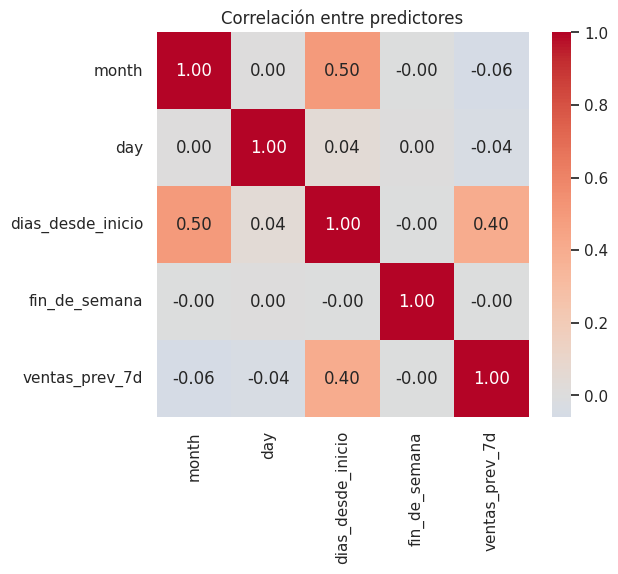

            Variable       VIF
0              const  1.000000
1              month  1.455825
2                day  1.006180
3  dias_desde_inicio  1.730260
4      fin_de_semana  1.000026
5     ventas_prev_7d  1.331648
                     R2        MAE       RMSE
Entrenamiento  0.074658  10.118780  12.668680
Prueba        -0.026601   9.509407  11.902013
Intercepto: 42.591213153577485
month               -0.599010
day                  0.055008
dias_desde_inicio    0.016208
fin_de_semana       -0.787558
ventas_prev_7d       0.152610
dtype: float64


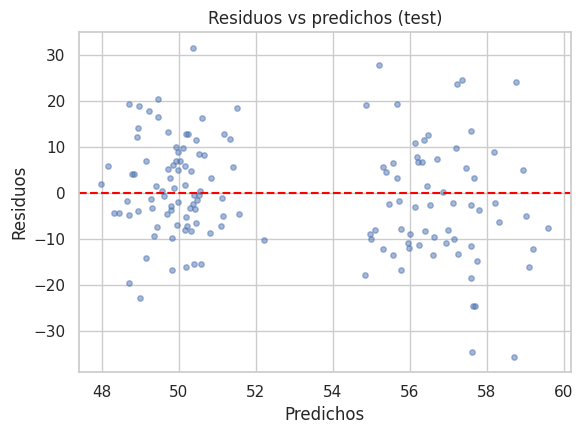

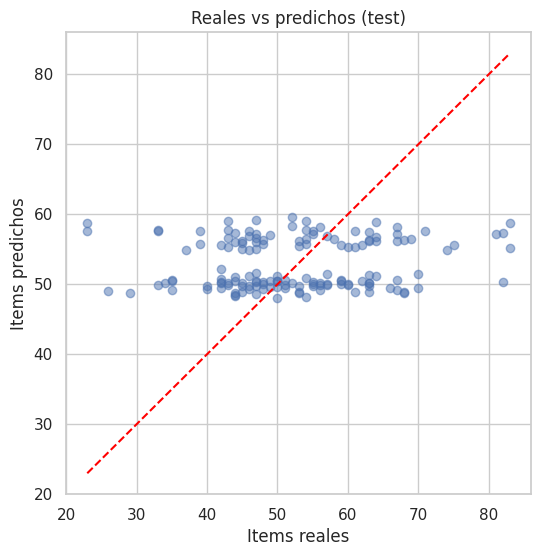

                     R2       MAE       RMSE      n
Entre semana  -0.042097  9.686538  12.264283  104.0
Fin de semana  0.014107  9.060100  10.929355   41.0


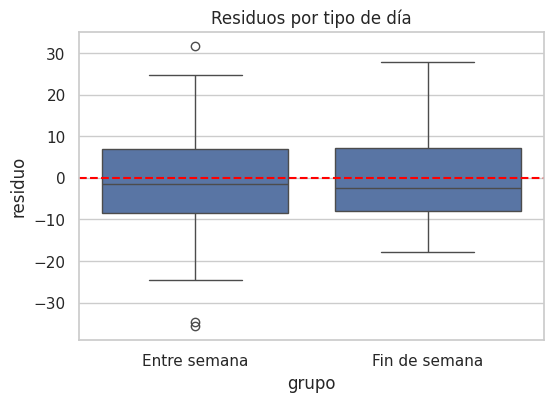

            R2        MAE       RMSE     n
2014 -0.011031   8.194299  10.318010  81.0
2015 -0.063285  11.173841  13.645644  64.0


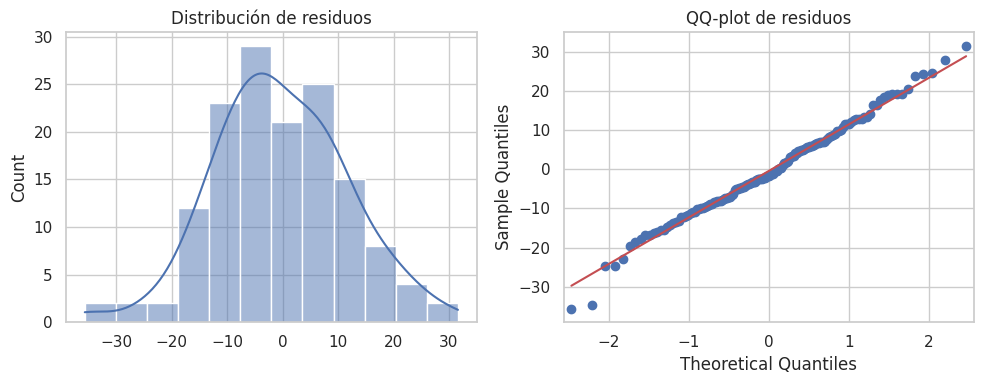

NameError: name 'durbin_watson' is not defined

In [42]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import kagglehub

# Definición de variables y funciones de soporte por si no se ejecutaron las celdas anteriores
RANDOM_STATE = 42

def metricas(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

def grafico_regresion(x, y, modelo, titulo):
    plt.figure(figsize=(6, 4.5))
    plt.scatter(x, y, alpha=0.5, s=15)
    xs = pd.DataFrame({x.name: np.linspace(x.min(), x.max(), 100)})
    plt.plot(xs[x.name], modelo.predict(xs), color="red")
    plt.xlabel(x.name); plt.ylabel(y.name); plt.title(titulo)
    plt.tight_layout(); plt.show()

def grafico_residuos(y_true, y_pred, titulo):
    res = np.asarray(y_true) - np.asarray(y_pred)
    plt.figure(figsize=(6, 4.5))
    plt.scatter(y_pred, res, alpha=0.5, s=15)
    plt.axhline(0, color="red", linestyle="--")
    plt.xlabel("Predichos"); plt.ylabel("Residuos"); plt.title(titulo)
    plt.tight_layout(); plt.show()

def hist_box(df, cols):
    fig, axes = plt.subplots(2, len(cols), figsize=(4.2 * len(cols), 6), squeeze=False)
    for j, c in enumerate(cols):
        sns.histplot(df[c].dropna(), kde=True, ax=axes[0, j]); axes[0, j].set_title(c)
        sns.boxplot(y=df[c].dropna(), ax=axes[1, j])
    plt.tight_layout(); plt.show()

def calcular_vif(df, predictores):
    X = df[predictores].dropna()
    X_with_const = sm.add_constant(X)
    vifs = [variance_inflation_factor(X_with_const.values, i) for i in range(X_with_const.shape[1])]
    vif_df = pd.DataFrame({"Variable": X_with_const.columns, "VIF": vifs})
    print(vif_df)

HANDLE = "rashikrahmanpritom/groceries-dataset-for-market-basket-analysismba"
ruta4= kagglehub.dataset_download(HANDLE)
print(os.listdir(ruta4))
ARCHIVO = "Groceries data.csv"
OBJETIVO = "columna_objetivo"
SEGMENTO = ""

df4 = pd.read_csv(os.path.join(ruta4, ARCHIVO))
print(df4.shape)
print(df4.dtypes)
print(df4.isnull().sum()[df4.isnull().sum() > 0])
df4.head()

raw = pd.read_csv(os.path.join(ruta4, ARCHIVO))
raw["Date"] = pd.to_datetime(raw["Date"])

diario = (raw.groupby("Date")
              .agg(items_vendidos=("itemDescription", "count"))
              .reset_index())

diario["year"] = diario["Date"].dt.year
diario["month"] = diario["Date"].dt.month
diario["day"] = diario["Date"].dt.day
diario["day_of_week"] = diario["Date"].dt.dayofweek
diario["fin_de_semana"] = (diario["day_of_week"] >= 5).astype(int)
diario["dias_desde_inicio"] = (diario["Date"] - diario["Date"].min()).dt.days
diario["ventas_prev_7d"] = diario["items_vendidos"].shift(1).rolling(7).mean()
diario["tipo_dia"] = np.where(diario["fin_de_semana"] == 1, "Fin de semana", "Entre semana")

df4 = diario
OBJETIVO = "items_vendidos"
SEGMENTO = "tipo_dia"

print(df4.shape, df4["Date"].min(), df4["Date"].max())
df4.describe()
hist_box(df4, ["items_vendidos", "ventas_prev_7d", "dias_desde_inicio"])

cols_corr = ["items_vendidos", "month", "day", "day_of_week", "fin_de_semana",
             "dias_desde_inicio", "ventas_prev_7d", "year"]

plt.figure(figsize=(8, 6))
sns.heatmap(df4[cols_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones (Groceries diario)"); plt.tight_layout(); plt.show()

corr_obj = df4[cols_corr].corr()["items_vendidos"].drop("items_vendidos").sort_values(key=abs, ascending=False)
print(corr_obj)

mejor4 = corr_obj.abs().idxmax()
d = df4[[mejor4, OBJETIVO]].dropna()
m_s = LinearRegression().fit(d[[mejor4]], d[OBJETIVO])
grafico_regresion(d[mejor4], d[OBJETIVO], m_s, f"{OBJETIVO} ~ {mejor4}")

plt.figure(figsize=(6, 4))
sns.boxplot(data=df4, x="tipo_dia", y="items_vendidos")
plt.title("Items vendidos por tipo de día"); plt.show()

predictores4 = ["month", "day", "dias_desde_inicio", "fin_de_semana", "ventas_prev_7d"]

heatmap_pred = df4[predictores4].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(heatmap_pred, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre predictores"); plt.show()

calcular_vif(df4, predictores4)

datos4 = df4[[OBJETIVO] + predictores4].dropna()
X_tr, X_te, y_tr, y_te = train_test_split(datos4[predictores4], datos4[OBJETIVO],
                                          test_size=0.2, random_state=RANDOM_STATE)

m4 = LinearRegression().fit(X_tr, y_tr)

tabla = pd.DataFrame({"Entrenamiento": metricas(y_tr, m4.predict(X_tr)),
                      "Prueba": metricas(y_te, m4.predict(X_te))}).T
print(tabla)

print("Intercepto:", m4.intercept_)
print(pd.Series(m4.coef_, index=predictores4))

pred_te = m4.predict(X_te)
grafico_residuos(y_te, pred_te, "Residuos vs predichos (test)")

plt.figure(figsize=(6, 6))
plt.scatter(y_te, pred_te, alpha=0.5)
lim = [y_te.min(), y_te.max()]
plt.plot(lim, lim, color="red", linestyle="--")
plt.xlabel("Items reales"); plt.ylabel("Items predichos"); plt.title("Reales vs predichos (test)")
plt.show()

pred_s = pd.Series(pred_te, index=X_te.index)
seg = df4.loc[X_te.index, SEGMENTO]

filas = {}
for g in seg.dropna().unique():
    idx = seg.index[seg == g]
    filas[g] = {**metricas(y_te.loc[idx], pred_s.loc[idx]), "n": len(idx)}
print(pd.DataFrame(filas).T)

res = pd.DataFrame({"residuo": y_te - pred_s, "grupo": seg})
plt.figure(figsize=(6, 4))
sns.boxplot(data=res, x="grupo", y="residuo")
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuos por tipo de día"); plt.show()

seg_y = df4.loc[X_te.index, "year"]
filas = {}
for g in seg_y.unique():
    idx = seg_y.index[seg_y == g]
    filas[g] = {**metricas(y_te.loc[idx], pred_s.loc[idx]), "n": len(idx)}
print(pd.DataFrame(filas).T)

residuos = y_te - pred_s
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(residuos, kde=True, ax=ax[0]); ax[0].set_title("Distribución de residuos")
sm.qqplot(residuos, line="s", ax=ax[1]); ax[1].set_title("QQ-plot de residuos")
plt.tight_layout(); plt.show()

res_orden = (df4.loc[datos4.index, OBJETIVO] - m4.predict(datos4[predictores4]))
print("Durbin-Watson:", durbin_watson(res_orden))